# 8. Interpretabilidad: SHAP y LIME

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** ¿Qué variables deciden el estrato que predice el modelo, en general y en una vivienda concreta?
¿Coinciden SHAP y LIME?

**Respuesta corta.** La ubicación y el entorno, no la vivienda: la posición norte-sur, la distancia al centro y
el área y los baños de los vecinos. El estrato 1 lo explica sobre todo la distancia al centro; el 6, el norte de
la ciudad y vecinos con viviendas grandes. LIME coincide solo en parte con SHAP y se aparta con variables
correlacionadas o binarias.
```

**SHAP** reparte la predicción de una vivienda entre sus variables con los **valores de Shapley** de la teoría de
juegos cooperativos: la contribución de una variable es su aporte marginal promedio sobre todas las coaliciones
posibles de las demás. Es la única atribución que cumple a la vez **eficiencia** (las contribuciones suman la
diferencia entre la predicción y el promedio), **simetría** (dos variables intercambiables reciben lo mismo) y
**aditividad**. Para XGBoost se calculan exactos con TreeSHAP; para otros modelos, por permutaciones.

**LIME** ajusta, alrededor de una vivienda, un modelo **lineal local** sobre perturbaciones de sus variables
(discretizadas en cuartiles) ponderadas por su cercanía. Es más barato, pero su explicación depende del radio
del vecindario y del muestreo, no garantiza que las contribuciones sumen la predicción y puede cambiar entre
corridas.

**Cuándo divergen.** Con variables correlacionadas (área, baños y habitaciones; x, y y distancia al centro) LIME
perturba cada una por separado y crea viviendas imposibles, mientras SHAP reparte el efecto entre las
correlacionadas. Con efectos muy no lineales o interacciones (la ubicación cambia el efecto del tamaño), una
aproximación lineal local puede ser mala lejos del punto. En esos casos sus rankings de variables difieren.

**Qué modelos se explican.** La guía pide SHAP para el mejor modelo de cada tarea y la comparación con LIME en
XGBoost. Se explican: **XGBoost** (TreeSHAP exacto), el **XGBoost geográfico** (el modelo nuevo) y el **mejor
finalista en el test** de clasificación (SHAP por permutaciones, que sirve para cualquier modelo), y el **mejor
modelo de regresión** (Random Forest, TreeSHAP exacto). Las explicaciones se calculan sobre viviendas del test
elegidas con la semilla fija; las variables están en la escala del preprocesamiento (estandarizadas), así que en
los *summary plots* el color indica valores bajos (azul) o altos (rojo) de cada variable.

## 8.1 Interpretabilidad global: clasificación

Mejor finalista en el test: Logística L1/L2


,XGBoost,XGBoost geográfico,Logística L1/L2
y_km,0.8408,0.0642,0.0284
knn8_log_area,0.5082,0.0270,0.0702
knn8_banios,0.5079,0.0220,0.0207
dist_centro_km,0.3184,0.0533,0.0436
x_km,0.2828,0.0484,0.0310
knn8_dist_km,0.2654,0.0152,0.0162
knn8_prop_PH,0.1481,0.0069,0.0101
knn8_piso,0.1450,0.0099,0.0210
knn8_habitaciones,0.0655,0.0065,0.0159
total_banios,0.0628,0.0022,0.0085


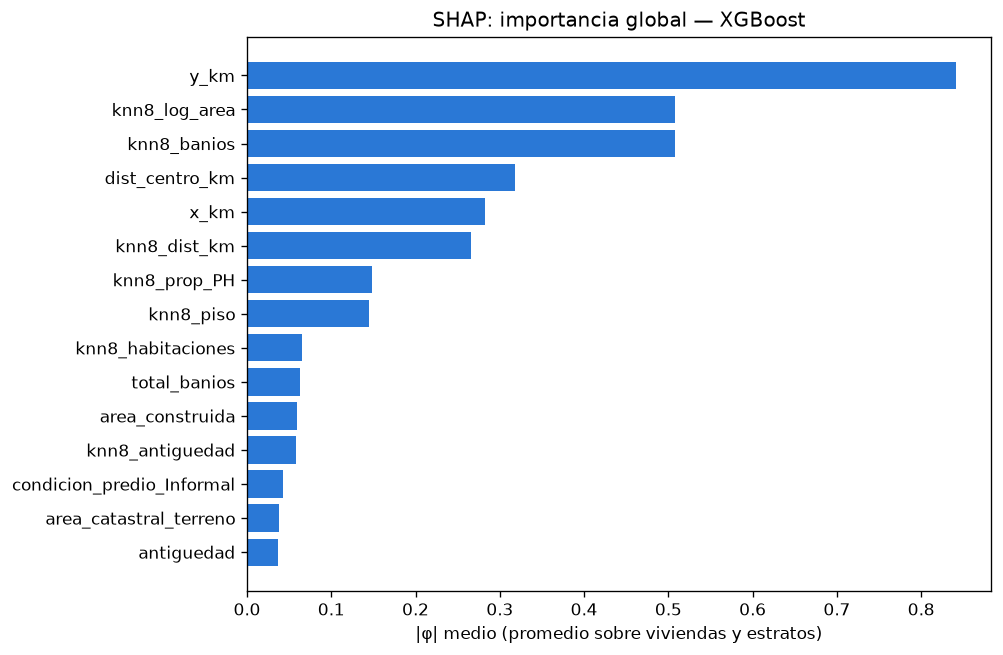

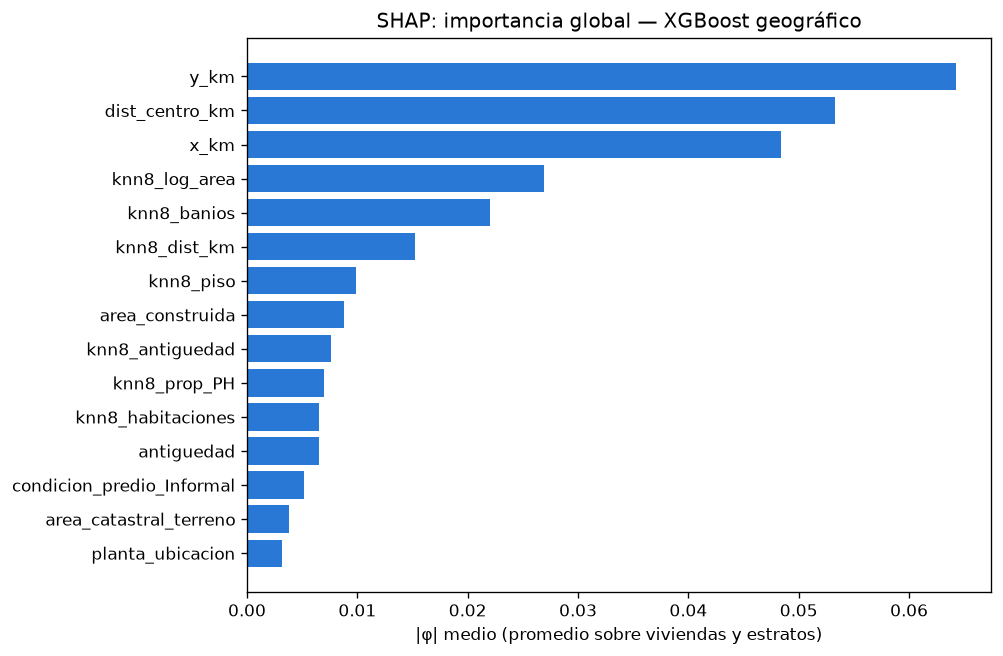

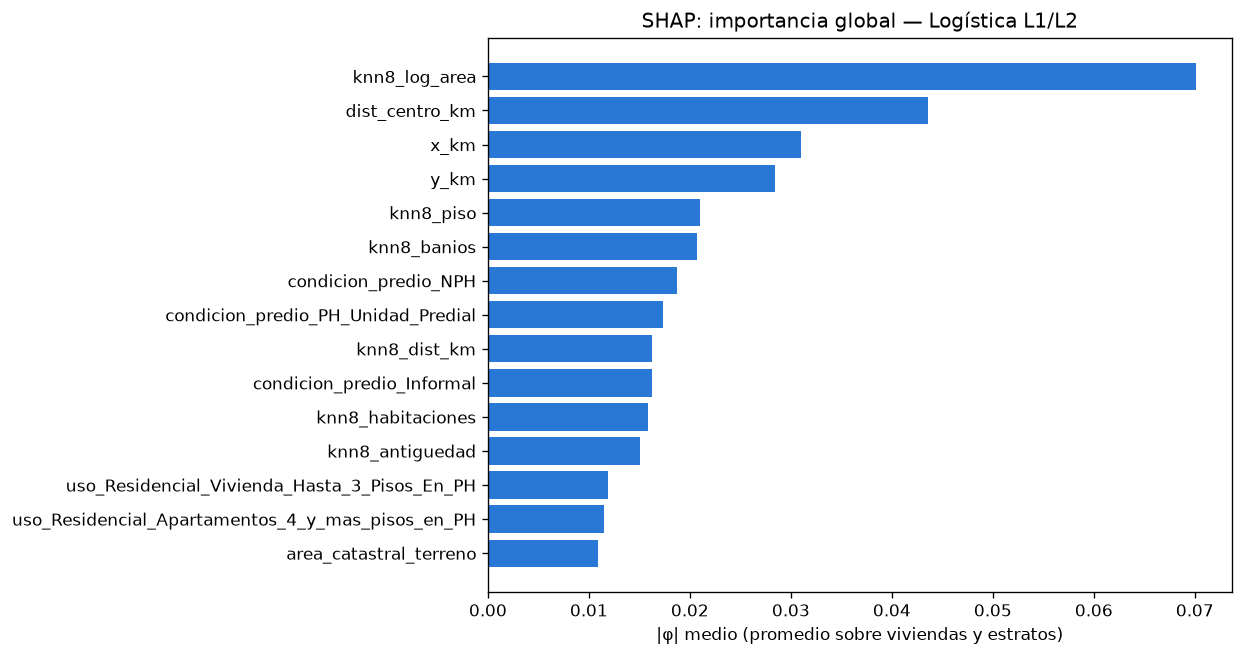

In [1]:
import pandas as pd

from _comun import figura, leer_json

IN = leer_json("interpretabilidad.json") or {}
IC = IN.get("clasificacion", {})


def arch(n):
    return n.replace(" ", "_").replace("/", "-").replace("(", "").replace(")", "")


if IC:
    print("Mejor finalista en el test:", IN.get("mejor_clasificacion_test"))
    display(pd.DataFrame({n: pd.Series(v["importancia_global"]) for n, v in IC.items()}).round(4)
            .sort_values(list(IC)[0], ascending=False).head(15))
for nombre in IC:
    figura(f"shap_global_{arch(nombre)}.png")

Los *summary plots* (beeswarm) muestran, para los estratos de los extremos, el efecto de cada variable en cada
vivienda: a la derecha empuja hacia ese estrato, a la izquierda lo aleja.

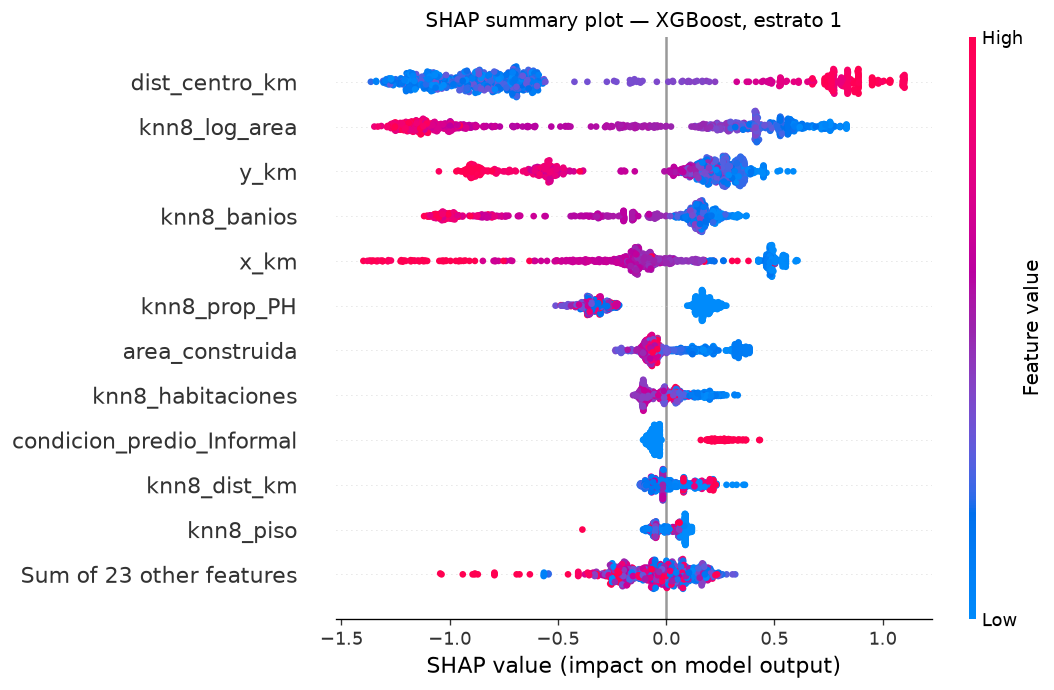

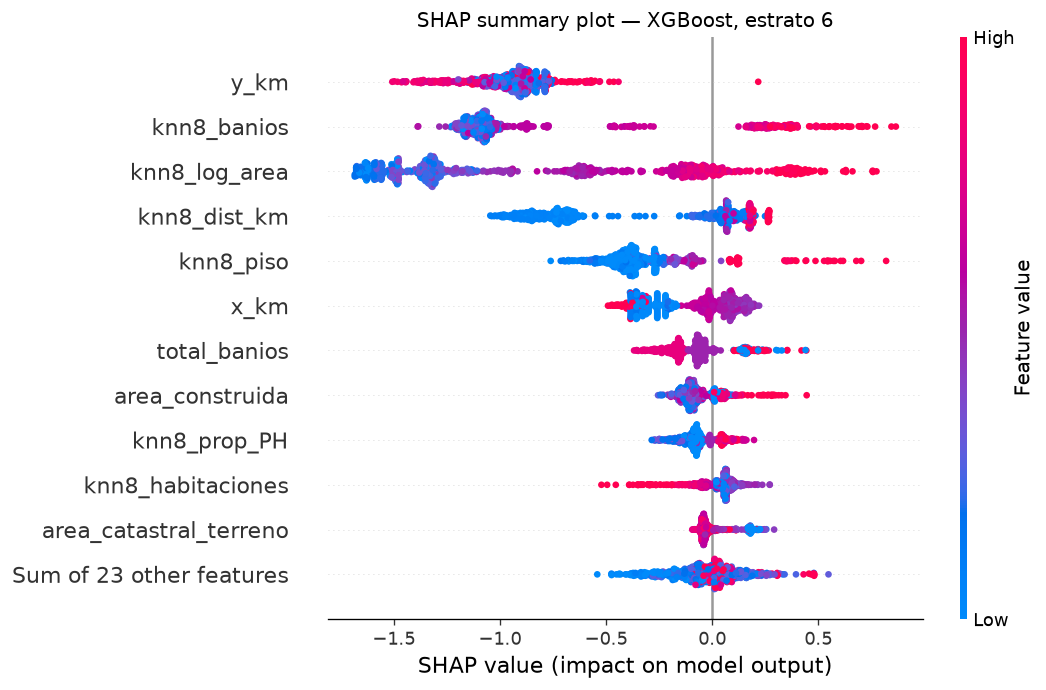

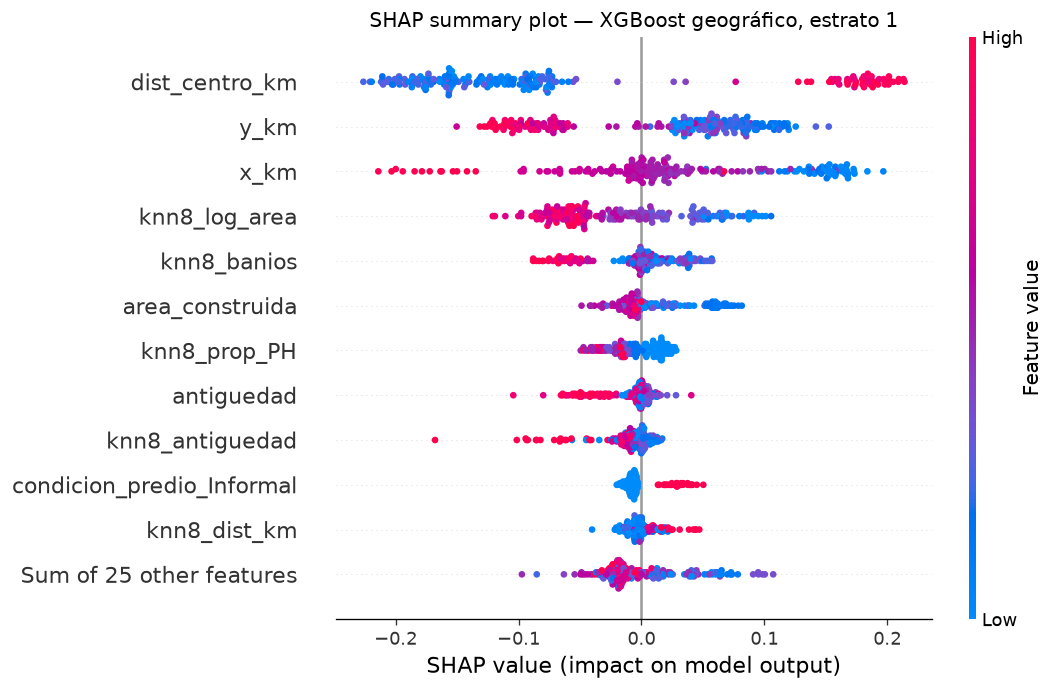

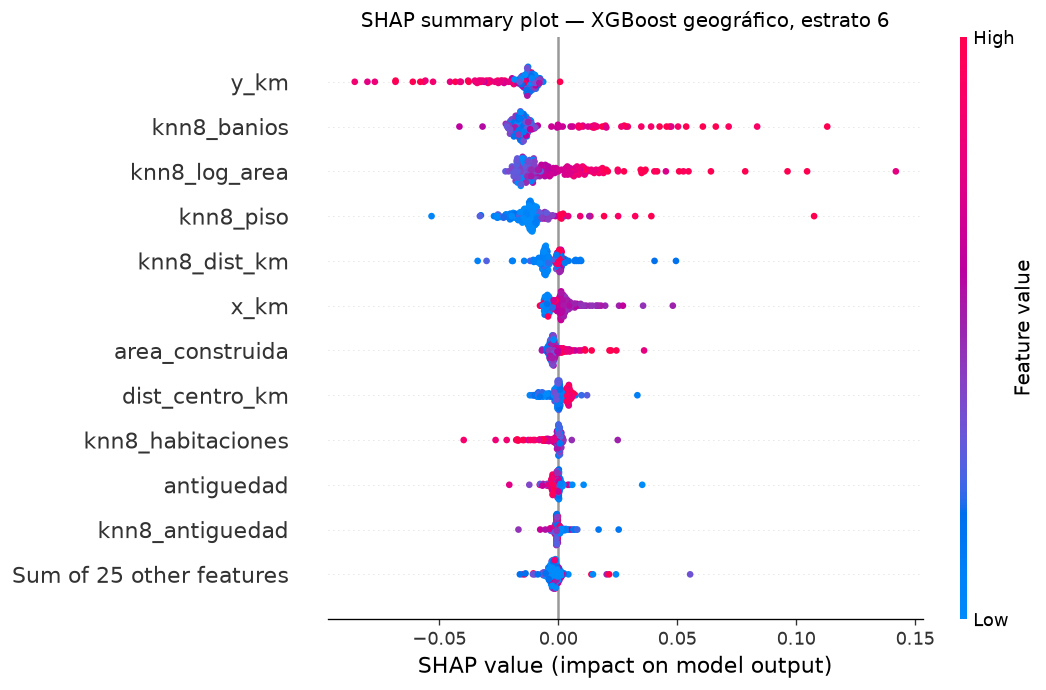

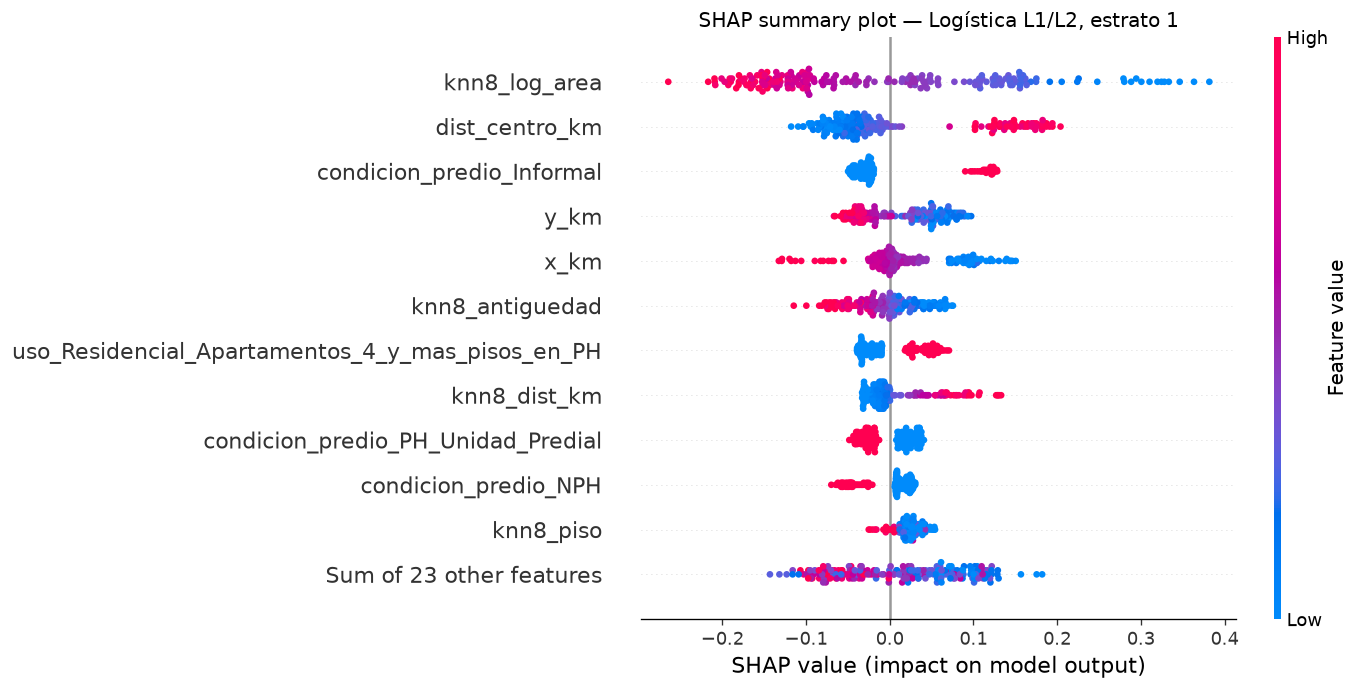

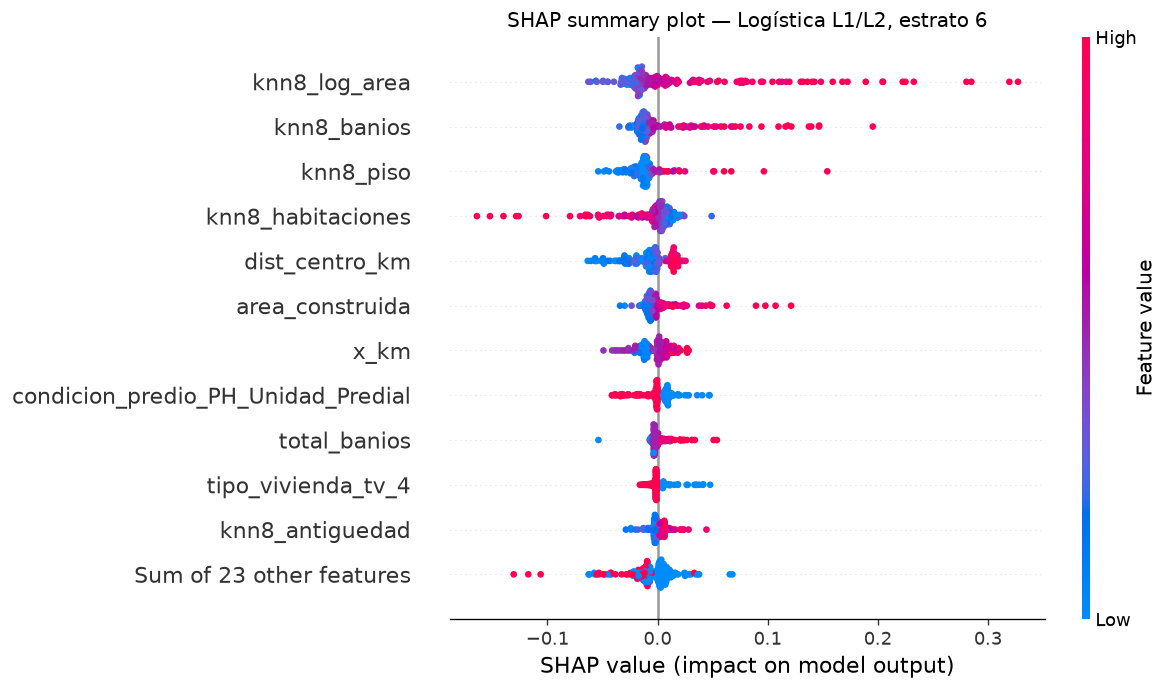

In [2]:
for nombre in IC:
    for k in [1, 6]:
        figura(f"shap_beeswarm_{arch(nombre)}_estrato{k}.png")

**Escalas.** En XGBoost, TreeSHAP reparte el *margen* del modelo (log-odds de cada estrato); en los modelos
explicados por permutaciones, la *probabilidad*. Por eso las magnitudes no se comparan entre modelos, pero el
orden de las variables sí.

**Lectura.** Los tres modelos cuentan la misma historia: **el estrato lo deciden la ubicación y el entorno, no
la vivienda.** En XGBoost, las variables más importantes son la posición norte-sur (`y_km`), el área y los
baños de los 8 vecinos (`knn8_log_area`, `knn8_banios`), la distancia al centro, la posición este-oeste y la
distancia típica a esos vecinos (`knn8_dist_km`, una medida de densidad); la primera variable propia de la
vivienda, sus baños, aparece en el décimo lugar con un peso 13 veces menor que `y_km`. En la logística el
orden es parecido (primero el área de los vecinos y la distancia al centro, luego las coordenadas), y aparece
la condición del predio (propiedad horizontal o no, informal) como única variable propia relevante.

Por estrato, los *summary plots* muestran mecanismos distintos para los dos extremos:

- **Estrato 1:** lo explica sobre todo la **distancia al centro** (en XGBoost, |φ| = 0.84, la mayor, seguida del área
  de los vecinos con 0.68) y que los vecinos tengan **viviendas pequeñas**: las viviendas lejanas del centro con vecinos de poca área
  empujan hacia el 1.
- **Estrato 6:** lo explican la **posición al norte** (`y_km`, |φ| = 0.95) y vecinos con **muchos baños y mucha
  área**; la distancia al centro casi no importa (0.06). Es la geografía conocida de Barranquilla: los estratos
  altos se concentran en el norte, no en un anillo alrededor del centro.

Esto explica también por qué la vecindad física mejora tanto al modelo base (capítulo 9): las variables que
más pesan son justo las que la logística B no tenía.

**El XGBoost geográfico** (en escala de probabilidad) ordena las variables igual que XGBoost: posición norte-
sur, distancia al centro, posición este-oeste y área y baños de los vecinos. Las coordenadas en km que solo
sirven para elegir el ancla de cada vivienda, `x_km (ancla)` e `y_km (ancla)`, casi no pesan (|φ| = 0.002 para
la *y*, frente a 0.064 de `y_km` como variable del modelo). Es lo esperable con α = 0.97: los modelos locales
reciben solo el 3 % del peso, así que cambiar de ancla casi no mueve la predicción. En los modelos explicados
en probabilidad, las contribuciones al estrato 6 son pequeñas porque ese estrato es raro en el test (1.2 %) y
su probabilidad casi siempre es baja.

## 8.2 Explicaciones locales: una vivienda bien clasificada y una con error grande

Gráficos *waterfall*: parten del valor base (la predicción promedio del modelo para ese estrato) y cada barra
suma o resta la contribución de una variable hasta llegar a la predicción de la vivienda (por la propiedad de
eficiencia, las contribuciones suman exactamente esa diferencia). Debajo, la explicación LIME de la misma
vivienda: sus reglas son intervalos de las variables y sus pesos los coeficientes del modelo lineal local.


XGBoost — bien clasificada: estrato real 1, predicho 1 (probabilidad 0.93); R² del modelo local de LIME = 0.38; variables en común entre los 8 primeros de SHAP y de LIME: 4


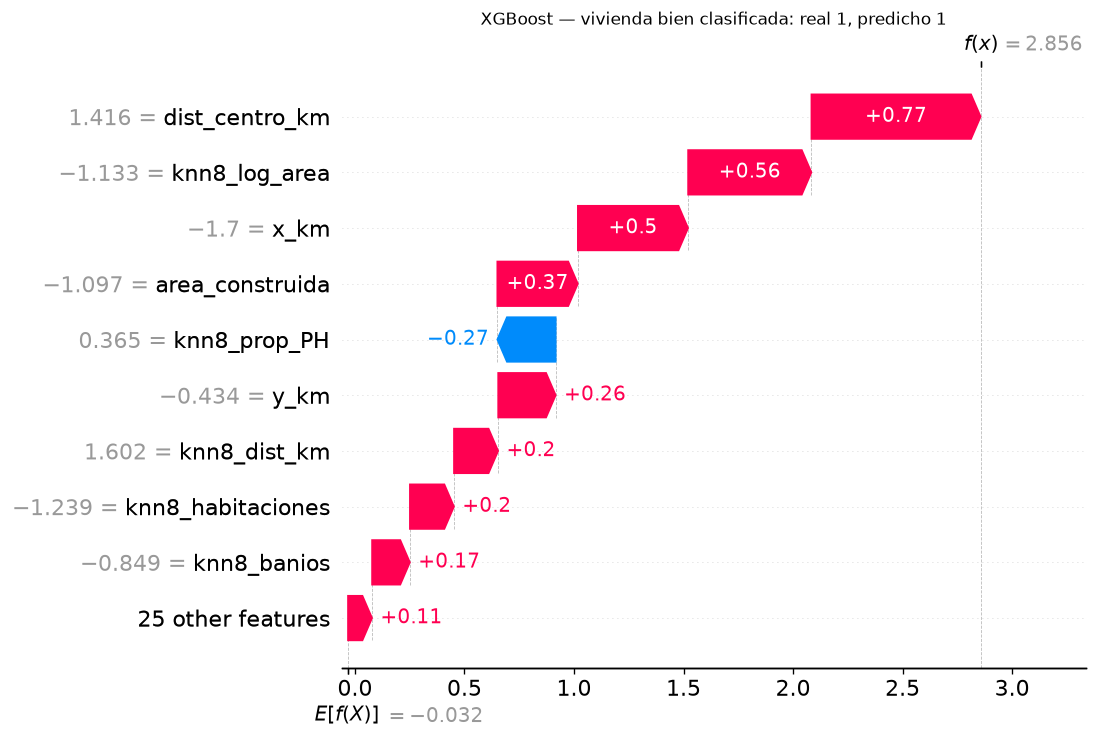

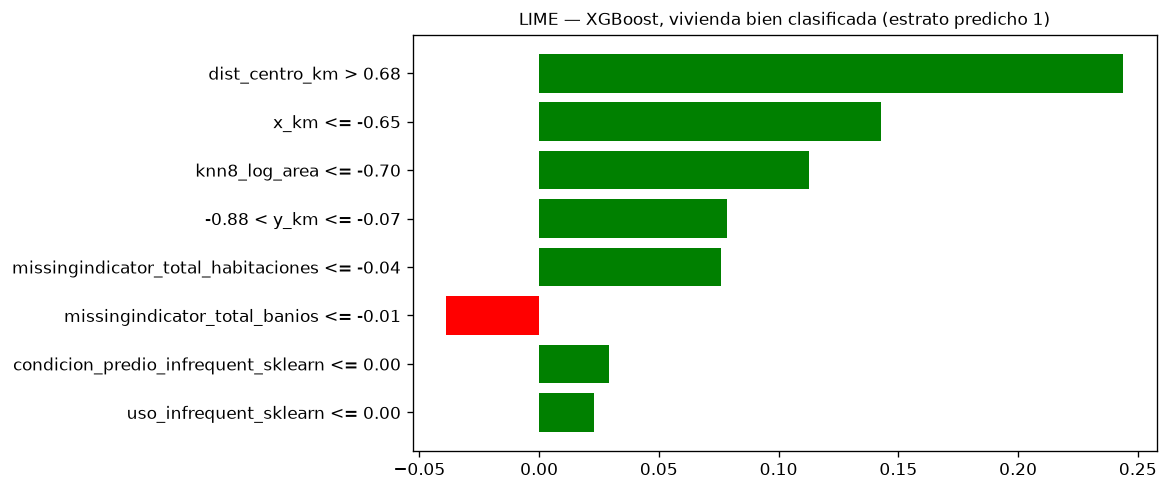


XGBoost — error grande: estrato real 2, predicho 4 (probabilidad 0.48); R² del modelo local de LIME = 0.12; variables en común entre los 8 primeros de SHAP y de LIME: 3


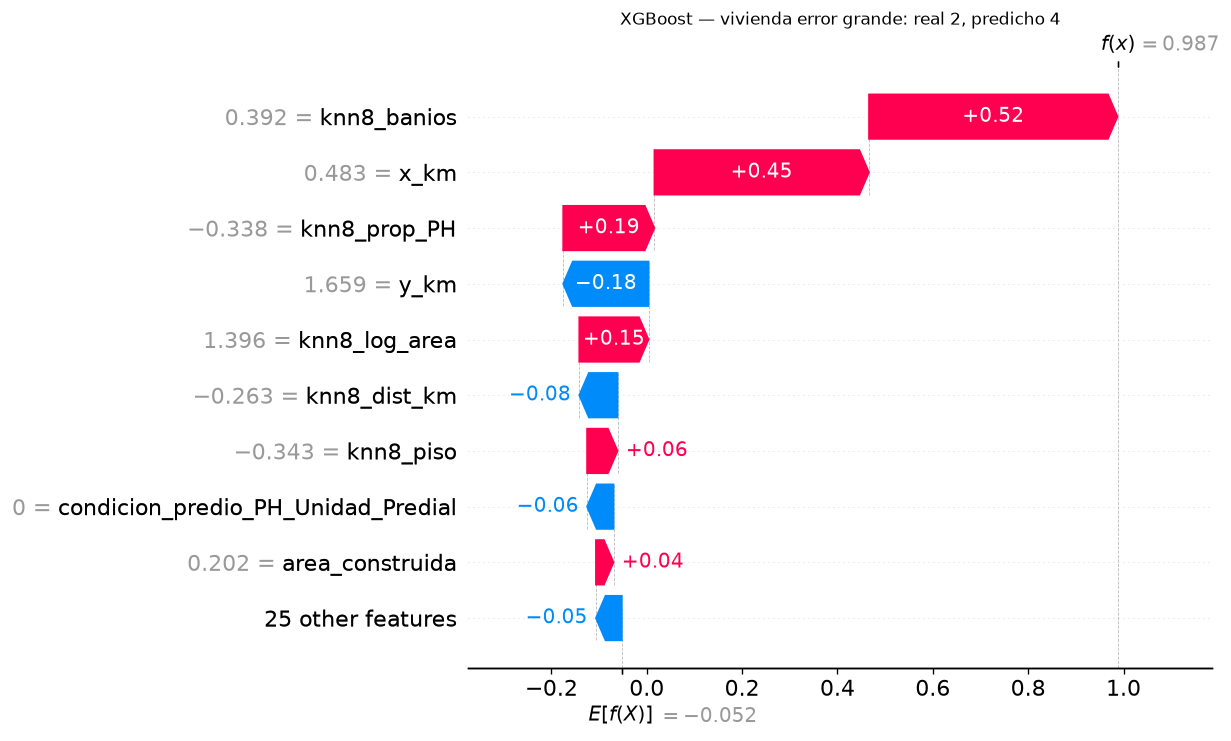

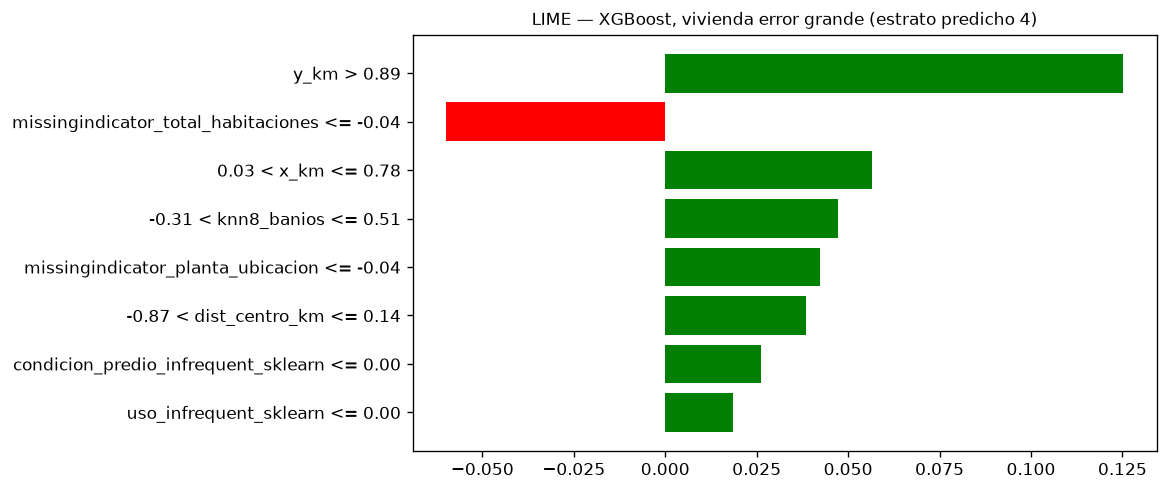


XGBoost geográfico — bien clasificada: estrato real 3, predicho 3 (probabilidad 0.44); R² del modelo local de LIME = 0.02; variables en común entre los 8 primeros de SHAP y de LIME: 1


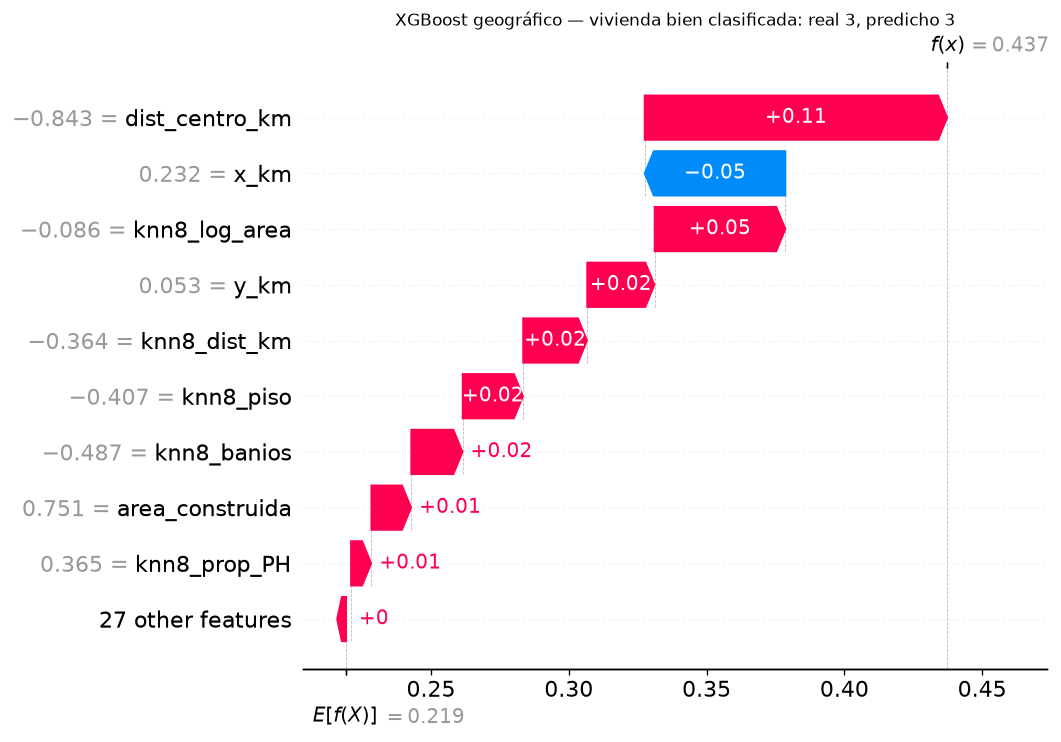

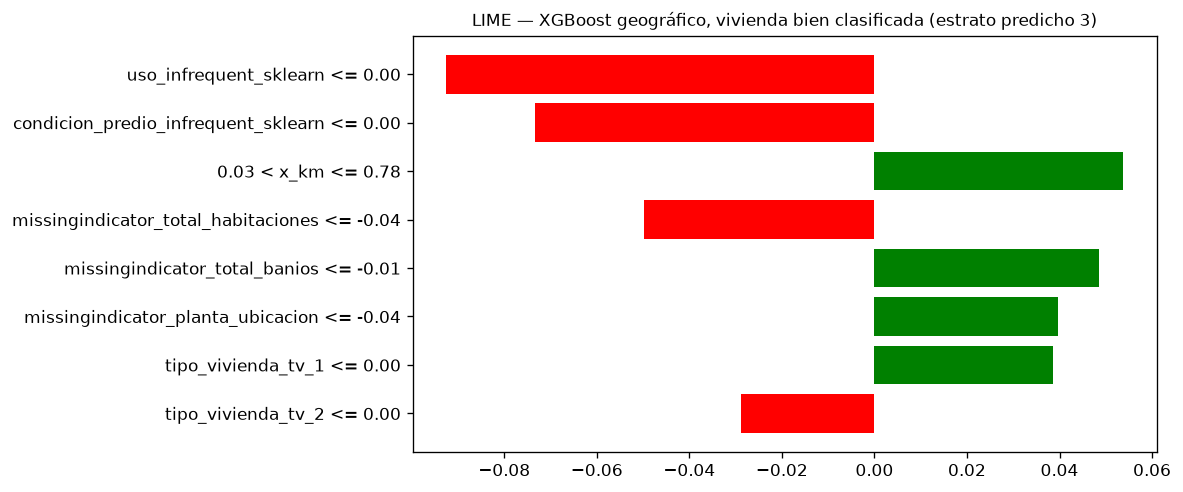


XGBoost geográfico — error grande: estrato real 4, predicho 2 (probabilidad 0.38); R² del modelo local de LIME = 0.08; variables en común entre los 8 primeros de SHAP y de LIME: 2


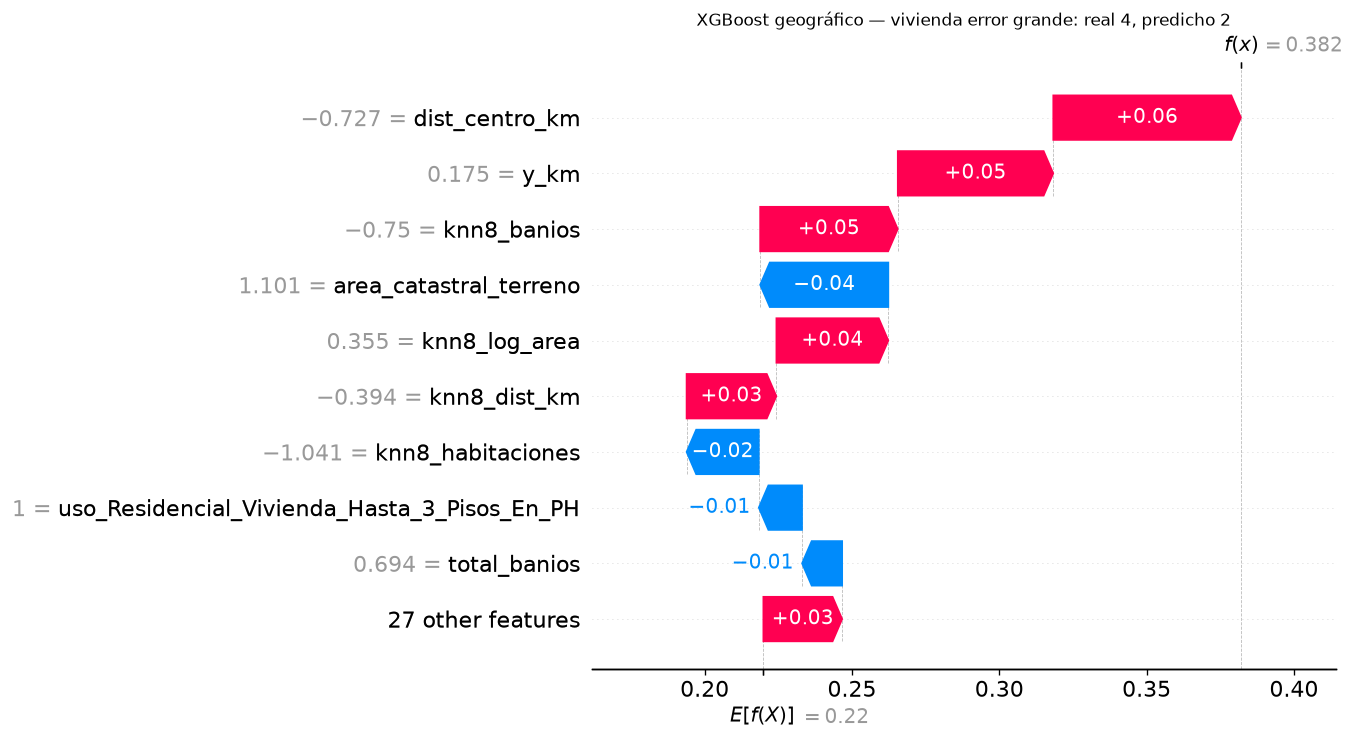

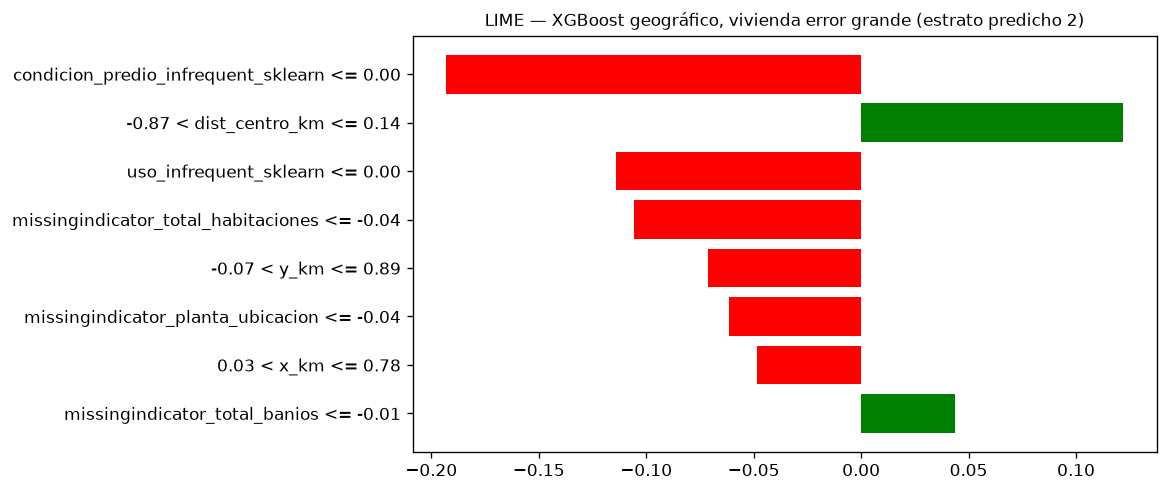


Logística L1/L2 — bien clasificada: estrato real 3, predicho 3 (probabilidad 0.56); R² del modelo local de LIME = 0.18; variables en común entre los 8 primeros de SHAP y de LIME: 4


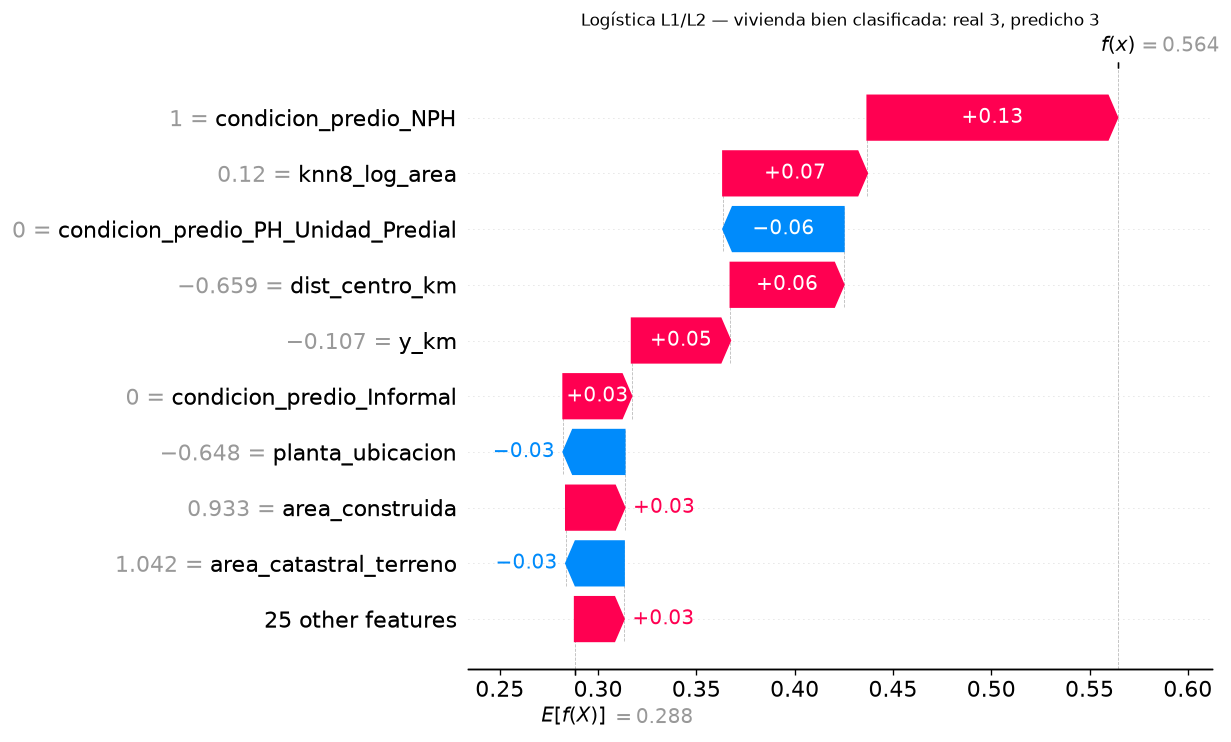

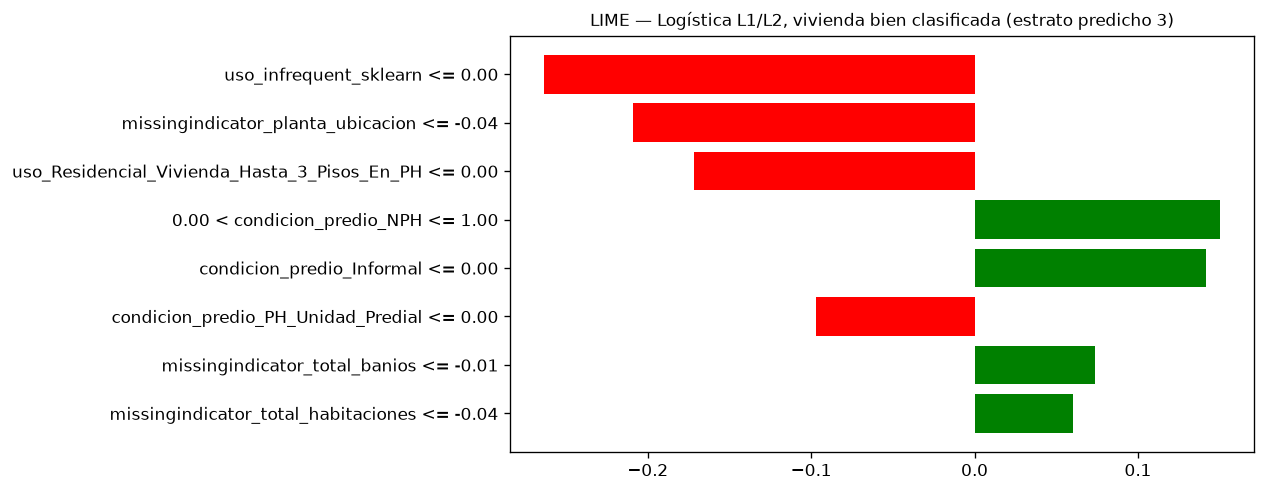


Logística L1/L2 — error grande: estrato real 3, predicho 5 (probabilidad 0.47); R² del modelo local de LIME = 0.29; variables en común entre los 8 primeros de SHAP y de LIME: 5


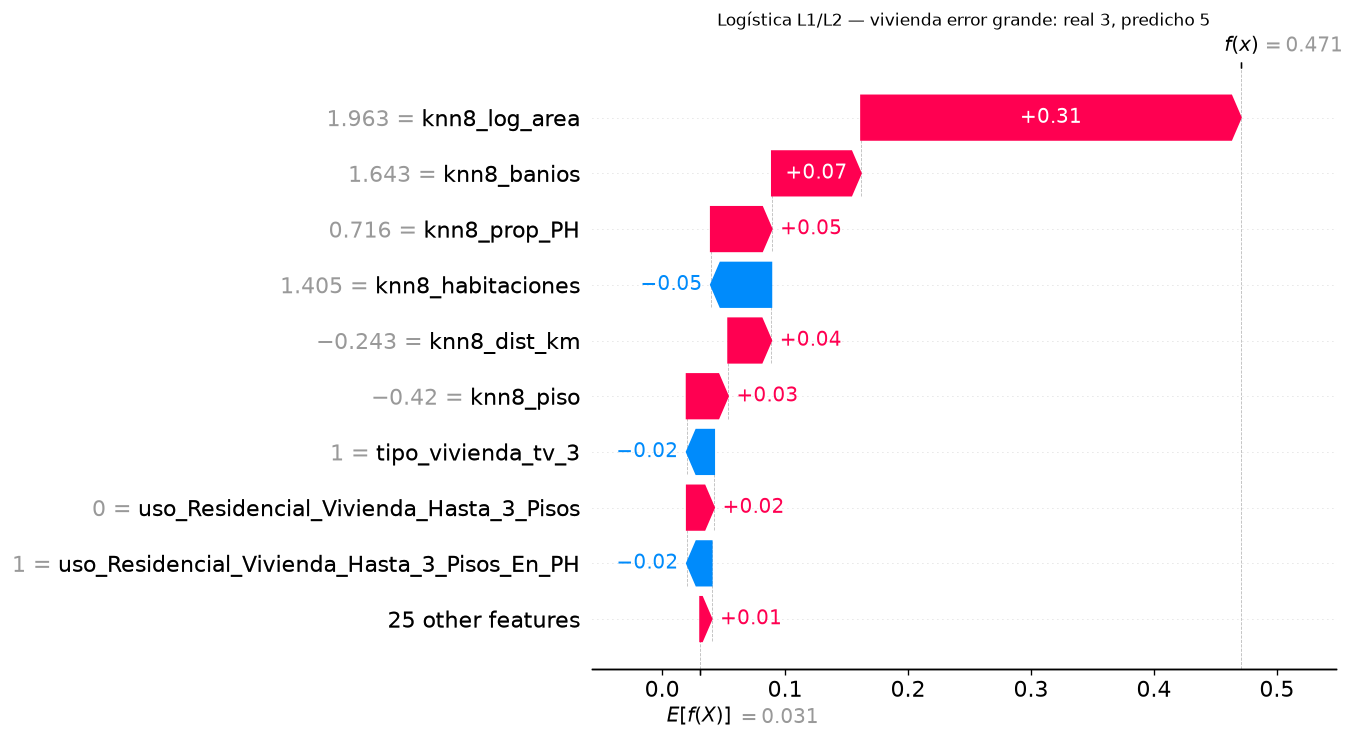

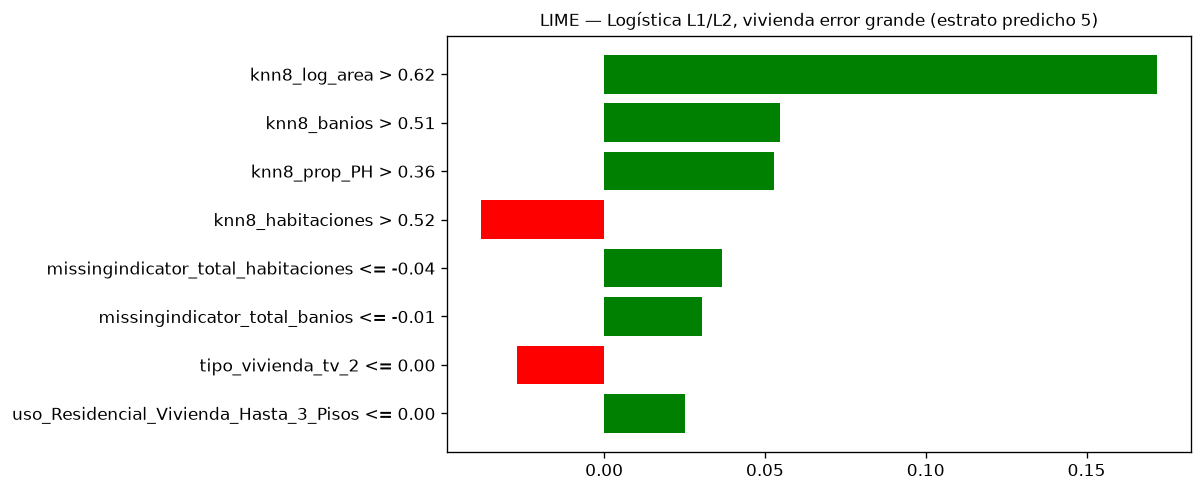

In [3]:
for nombre, v in IC.items():
    for etq, loc in v["locales"].items():
        print(f"\n{nombre} — {etq.replace('_', ' ')}: estrato real {loc['real']}, predicho {loc['predicho']} "
              f"(probabilidad {loc['probabilidad']:.2f}); R² del modelo local de LIME = {loc['lime_r2_local']:.2f}; "
              f"variables en común entre los 8 primeros de SHAP y de LIME: {len(loc['variables_en_comun_top8'])}")
        figura(f"shap_waterfall_{arch(nombre)}_{etq}.png")
        figura(f"lime_{arch(nombre)}_{etq}.png")

**Lectura de los casos.**

- **XGBoost, vivienda bien clasificada** (estrato 1, probabilidad 0.93): la empujan hacia el 1 su distancia al
  centro (+0.77 en el margen), el área pequeña de sus vecinos (+0.56) y su posición al oeste (+0.50). LIME coincide en
  las mismas cuatro variables de ubicación y entorno, con reglas del tipo «distancia al centro alta» y «área de los
  vecinos baja».
- **XGBoost, error grande** (estrato 2 predicho como 4, probabilidad 0.48): sus vecinos tienen muchos baños (+0.52)
  y su posición este-oeste es la de barrios de estrato 4 (+0.45). Es una vivienda modesta en una zona de transición:
  el modelo ve el barrio, no la casa.
- **Logística, error grande** (estrato 3 predicho como 5): el área grande de sus vecinos (+0.31) domina la
  predicción. Mismo patrón: una vivienda de estrato medio rodeada de viviendas grandes.

**SHAP frente a LIME.** Coinciden en 3 a 5 de las 8 variables principales en XGBoost y la logística, y en 1 o
2 en el XGBoost geográfico. Divergen justo donde la teoría lo anticipa:

1. **Calidad de la aproximación lineal local:** el R² del modelo lineal de LIME va de 0.02 a 0.38. Con interacciones
   fuertes (el efecto del tamaño cambia con la ubicación), una recta local explica poco de la superficie de
   decisión de los árboles.
2. **Variables binarias y correlacionadas:** LIME perturba cada variable por separado y crea viviendas imposibles
   (un predio con indicadores de faltante encendidos al azar, o con `x_km` cambiado sin cambiar `dist_centro_km`).
   Por eso aparecen en su lista indicadores de faltante y categorías «infrecuentes» que SHAP considera
   irrelevantes. SHAP, en cambio, reparte el efecto entre variables correlacionadas y sus contribuciones suman
   exactamente la predicción (propiedad de eficiencia).
3. **Inestabilidad:** las reglas de LIME dependen de la discretización en cuartiles y del muestreo; las de SHAP,
   del fondo y, en las permutaciones, de la semilla, que aquí está fija.

Para este problema, SHAP es la explicación más confiable; LIME sirve como verificación rápida cuando las dos
coinciden.

## 8.3 Regresión: el mejor modelo del estrato como número

Modelo: Random Forest (regresión) | Grid {'n_estimators': 150, 'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 2}


,|φ| medio (estratos)
knn8_banios,0.3036
y_km,0.2766
dist_centro_km,0.2738
knn8_log_area,0.2418
x_km,0.0917
knn8_prop_PH,0.0900
knn8_piso,0.0606
knn8_dist_km,0.0485
area_construida,0.0404
total_banios,0.0334


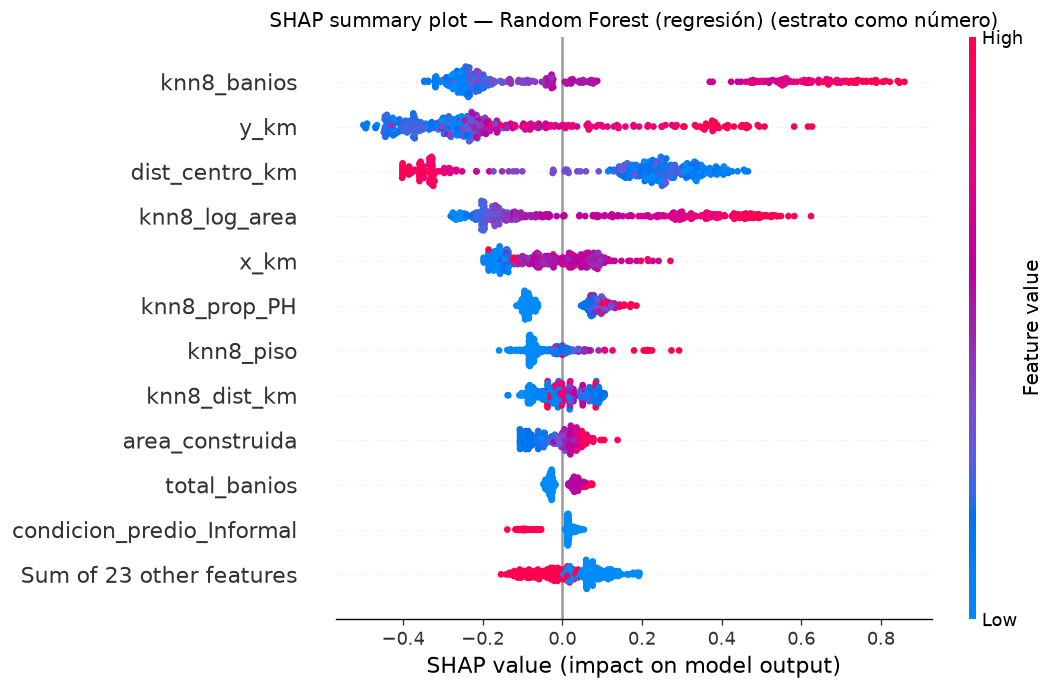


bien predicha: estrato real 3, predicho 2.86


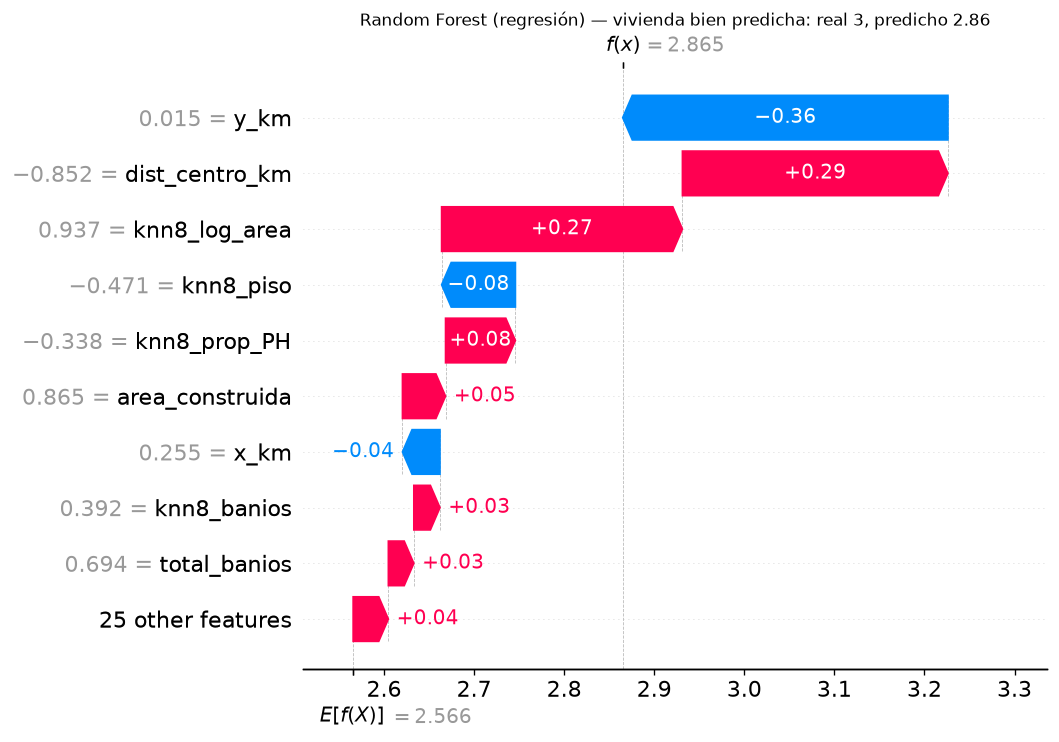


error grande: estrato real 5, predicho 2.92


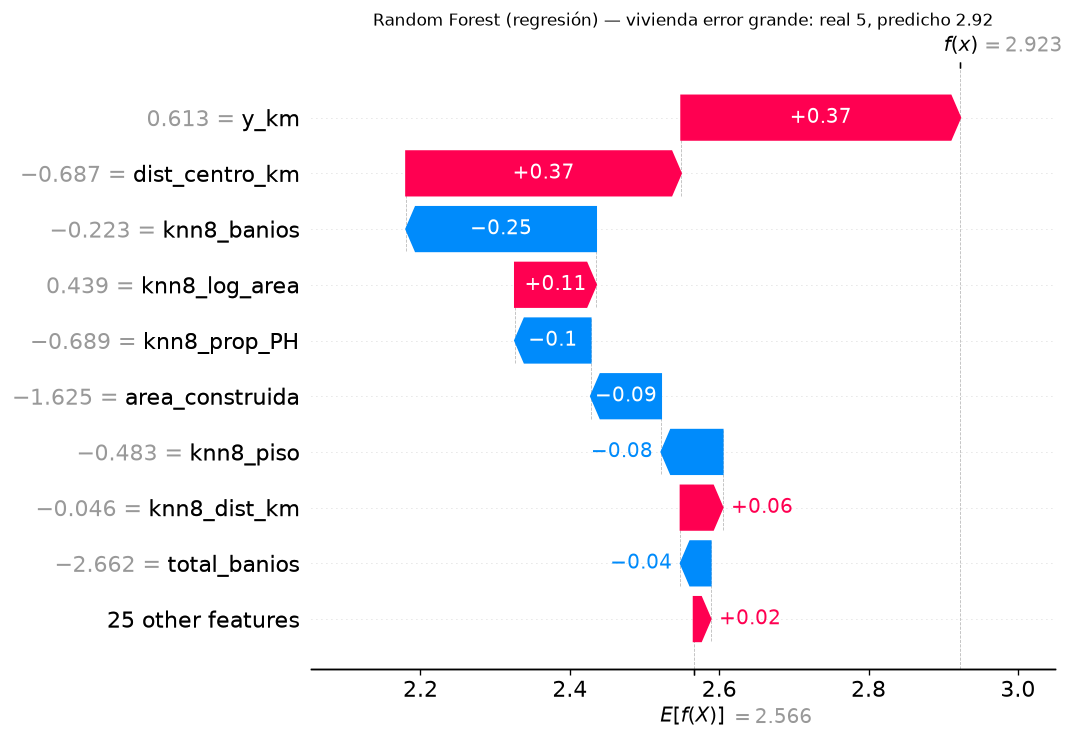

In [4]:
IR = IN.get("regresion")
if IR:
    print("Modelo:", IR["modelo"], IR["params"])
    display(pd.Series(IR["importancia_global"], name="|φ| medio (estratos)").round(4).head(15).to_frame())
    figura(f"shap_beeswarm_{arch(IR['modelo'].split(' | ')[0])}.png")
    for etq, loc in IR["locales"].items():
        print(f"\n{etq.replace('_', ' ')}: estrato real {loc['real']:.0f}, predicho {loc['predicho']:.2f}")
        figura(f"shap_waterfall_{arch(IR['modelo'].split(' | ')[0])}_{etq}.png")

**Lectura.** En el mejor modelo de regresión (Random Forest, estrato como número), las cuatro variables más
importantes son las mismas de la clasificación: baños y área de los vecinos, posición norte-sur y distancia al
centro, con |φ| medio de 0.24 a 0.30 estratos cada una; la primera variable propia de la vivienda (su área
construida) aporta 0.04. Los *waterfalls* parten del valor base de 2.57 (el estrato medio de la submuestra):

- **Bien predicha** (estrato 3, predicción 2.86): su posición al sur la baja (−0.36), pero la distancia al centro y
  el área de sus vecinos la suben (+0.29 y +0.27).
- **Error grande** (estrato 5, predicción 2.92): su ubicación la sube (+0.37 por `y_km` y +0.37 por la distancia al
  centro), pero sus vecinos tienen pocos baños (−0.25). Es el caso simétrico al de la clasificación: una vivienda de
  estrato alto en un entorno modesto. La regresión además comprime los extremos (capítulo 6), así que no se atreve
  a predecir un 5.